# Customer Churn Prediction

## 1. Data Loading and Exploration

The objective is to analyze customer churn
and identify the factors influencing customer
decisions to leave the company.

In [211]:
import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

In [212]:
data_path = "Data/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(data_path)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [213]:
X = df.drop(["Churn", "customerID"], axis=1)

y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 19)
Testing data: (1409, 19)


In [214]:
print("Dataset Shape:", X_train.shape)

print("\nData Types:")
print(X_train.dtypes)

print("\nMissing Values:")
print(X_train.isnull().sum())

print("\nDuplicate Rows:")
print(X_train.duplicated().sum())

print("\nClass Balance:")
print(y_train.value_counts())

Dataset Shape: (5634, 19)

Data Types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
dtype: object

Missing Values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
To

In [215]:
print("Missing Values:")
print(X_train.isnull().sum().to_string())

print("\nDuplicate Rows:")
print(X_train.duplicated().sum())

print("\nBlank TotalCharges:")
print(X_train["TotalCharges"].str.strip().eq("").sum())

Missing Values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0

Duplicate Rows:
26

Blank TotalCharges:
8


In [216]:
# Convert blank spaces into missing values
X_train["TotalCharges"] = X_train["TotalCharges"].str.strip()

X_train["TotalCharges"] = pd.to_numeric(
    X_train["TotalCharges"],
    errors="coerce"
)

print("Missing values after conversion:")
print(X_train["TotalCharges"].isnull().sum())

Missing values after conversion:
8


In [217]:
median_value = X_train["TotalCharges"].median()

X_train["TotalCharges"] = X_train["TotalCharges"].fillna(median_value)

print("Missing values after filling:")
print(X_train["TotalCharges"].isnull().sum())

Missing values after filling:
0


In [218]:
print("Total duplicate rows:", X_train.duplicated().sum())

print("Total training rows:", len(X_train))

Total duplicate rows: 26
Total training rows: 5634


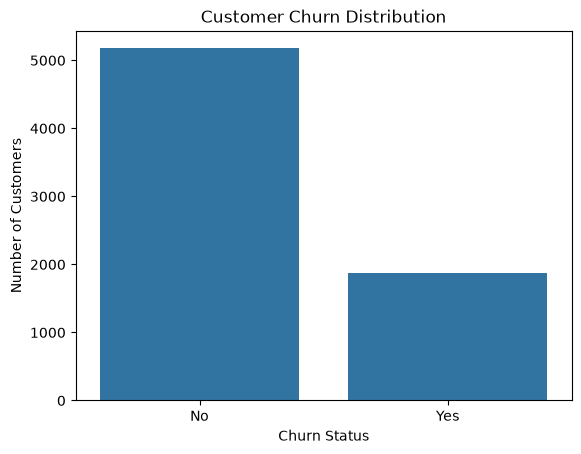

In [219]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

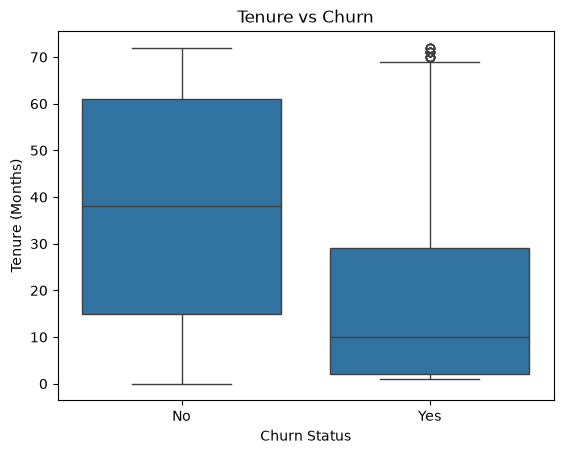

In [220]:
eda_df = X_train.copy()
eda_df["Churn"] = y_train

eda_df.head()

sns.boxplot(data=eda_df, x="Churn", y="tenure")

plt.title("Tenure vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.show()

### Observation – Tenure vs Churn

Customers who stayed with the company had a higher median tenure.
Customers who churned had a lower median tenure.
This suggests that customers with shorter tenure are more likely to churn.

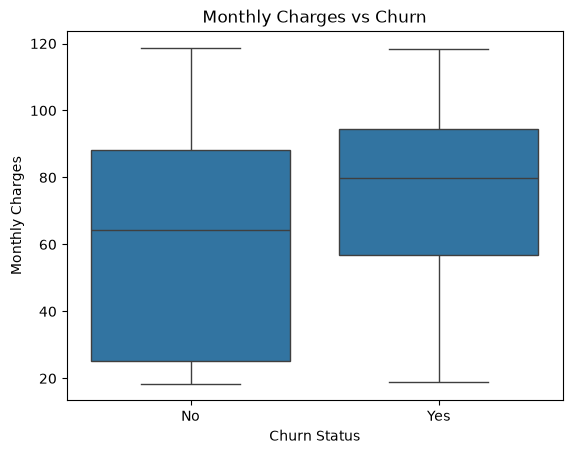

In [221]:
sns.boxplot(data=eda_df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")
plt.show()

### Observation – Monthly Charges vs Churn

Customers who churned had a higher median monthly charge
compared to customers who stayed.

This suggests that customers paying higher monthly charges
may be more likely to churn.

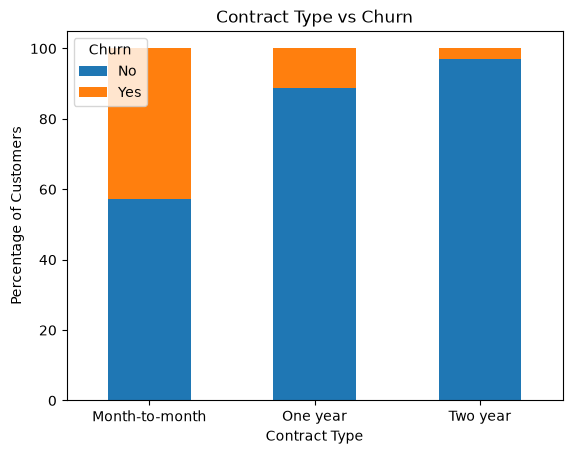

In [222]:
contract_churn = pd.crosstab(
    eda_df["Contract"],
    eda_df["Churn"],
    normalize="index"
) * 100

contract_churn.plot(kind="bar", stacked=True)

plt.title("Contract Type vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.show()

### Observation – Contract Type vs Churn

Month-to-month contract customers have the highest churn rate.

One-year contract customers have a lower churn rate.

Two-year contract customers have the lowest churn rate.

This suggests that customers with longer contracts
are less likely to churn.

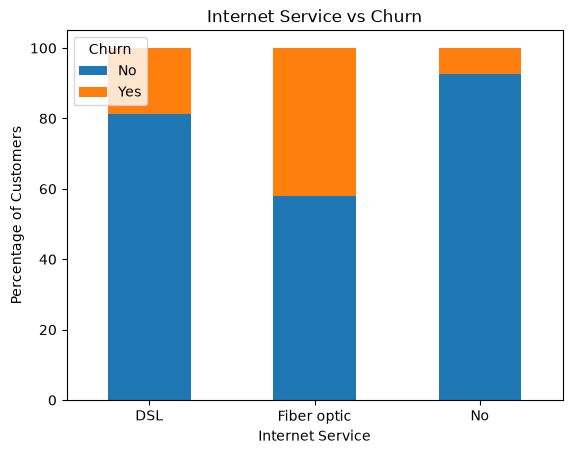

In [223]:
internet_churn = pd.crosstab(
    eda_df["InternetService"],
    eda_df["Churn"],
    normalize="index"
) * 100

internet_churn.plot(kind="bar", stacked=True)

plt.title("Internet Service vs Churn")
plt.xlabel("Internet Service")
plt.ylabel("Percentage of Customers")
plt.legend(title="Churn")
plt.xticks(rotation=0)
plt.show()

### Observation – Internet Service vs Churn

Fiber optic customers have the highest churn rate.

DSL customers have a lower churn rate.

Customers without internet service have the lowest churn rate.

This suggests that internet service type may influence
customer churn.

## 2. Assumptions and Evaluation Metric

### Assumptions

1. Churn is the target variable.
2. CustomerID is an identifier and is not useful for prediction.
3. Customer tenure and monthly charges may influence churn.
4. Contract type and internet service may influence churn.
5. Missing TotalCharges values are treated as missing data and filled using the training median.

### Evaluation Metric: F1-Score

F1-score is selected because the dataset has more non-churn customers than churn customers.

F1-score balances Precision and Recall. It helps identify customers who may churn while avoiding too many incorrect predictions.

In [224]:
X = df.drop(["Churn", "customerID"], axis=1).copy()
y = df["Churn"]

X["TotalCharges"] = pd.to_numeric(
    X["TotalCharges"].str.strip(),
    errors="coerce"
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Missing TotalCharges in training:", X_train["TotalCharges"].isnull().sum())

Training data: (5634, 19)
Testing data: (1409, 19)
Missing TotalCharges in training: 8


In [225]:
numeric_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("Numerical columns:", numeric_features)
print("Number of categorical columns:", len(categorical_features))

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Number of categorical columns: 15


In [226]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [227]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [228]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)

print("Processed training shape:", X_train_processed.shape)

Processed training shape: (5634, 45)


In [229]:
X_test_processed = preprocessor.transform(X_test)

print("Processed testing shape:", X_test_processed.shape)

Processed testing shape: (1409, 45)


In [230]:
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_processed, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [231]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [232]:
lr_predictions = log_model.predict(X_test_processed)

rf_predictions = rf_model.predict(X_test_processed)

print("Logistic Regression Predictions:")
print(lr_predictions[:10])

print("\nRandom Forest Predictions:")
print(rf_predictions[:10])

Logistic Regression Predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']

Random Forest Predictions:
['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes']


In [233]:
print("Logistic Regression Results")
print("Accuracy:", accuracy_score(y_test, lr_predictions))
print("Precision:", precision_score(y_test, lr_predictions, pos_label="Yes"))
print("Recall:", recall_score(y_test, lr_predictions, pos_label="Yes"))
print("F1-Score:", f1_score(y_test, lr_predictions, pos_label="Yes"))

print("\nRandom Forest Results")
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions, pos_label="Yes"))
print("Recall:", recall_score(y_test, rf_predictions, pos_label="Yes"))
print("F1-Score:", f1_score(y_test, rf_predictions, pos_label="Yes"))

Logistic Regression Results
Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1-Score: 0.6040462427745664

Random Forest Results
Accuracy: 0.7778566359119943
Precision: 0.6033898305084746
Recall: 0.47593582887700536
F1-Score: 0.5321375186846039


## 3. Model Performance Comparison

Two classification models were trained and evaluated.

| Model | Accuracy | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|
| Logistic Regression | 0.806 | 0.657 | 0.559 | 0.604 |
| Random Forest | 0.778 | 0.603 | 0.476 | 0.532 |

### Conclusion

Logistic Regression achieved a higher F1-score of 0.604 compared to Random Forest's 0.532.

Therefore, Logistic Regression is selected as the better model for this customer churn prediction task.

F1-score was used because it balances precision and recall, which is important when identifying customers likely to churn.